# Modelado: riesgo de retraso en la salida (`DepDel15`)

Lee la **capa silver** (salida de `flight_delay_eda_leakage.ipynb`: 19 columnas, sin columnas con fuga ni objetivos nulos) y compara:

| Modelo | Rol |
|---|---|
| Regresión logística | Línea base (según la propuesta) |
| LightGBM, solo variables estáticas | Modelo principal sin historial |
| LightGBM + patrones históricos | **Modelo principal** |
| LightGBM + patrones históricos + peso de clases | Experimento de desbalance |

**Decisiones de diseño**

- **Partición cronológica** (entrenamiento / validación / prueba). La prueba nunca se usa para elegir nada: el umbral y la parada temprana se deciden en validación.
- **Sin rebalancear** (propuesta, sección *Modelado*): no se remuestrea ni se pondera en los modelos principales para no distorsionar las probabilidades. El desbalance se maneja con las métricas (PR-AUC, lift, umbral elegido) y se mide su efecto en un experimento aparte.
- **Patrones históricos** (propuesta, semana 4): tasas de retraso por aeropuerto, ruta, aerolínea, matrícula y aeropuerto×hora, calculadas **solo con días estrictamente anteriores** a cada vuelo. Una celda verifica a mano que no haya fuga.
- **No se usa `Year`** como variable: el periodo de prueba está en años posteriores y un árbol no puede extrapolar.

## 0. Configuración

In [2]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import lightgbm as lgb
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             log_loss, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [3]:
SILVER_GLOB = "../data/silver/flights/**/*.parquet"
OUT_DIR     = Path("../outputs/outputs_modeling")
TARGET      = "DepDel15"
SEED        = 42

MEMORY_LIMIT = "8GB"
TEMP_DIR     = "duckdb_tmp"

# Partición cronológica (fechas inclusivas). Prueba = todo lo posterior a VAL_END.
TRAIN_END   = "2024-12-31"
VAL_END     = "2025-08-31"
WARMUP_DAYS = 60            # los primeros días no tienen historial: no se usan para entrenar

# Tamaño de las muestras. None = todo el tramo.
# Para la corrida final conviene subir N_TRAIN / N_EVAL (o dejar None si la memoria alcanza).
N_TRAIN  = 2_000_000
N_EVAL   = 1_000_000        # validación y prueba
N_LOGREG = 1_000_000        # filas de entrenamiento de la regresión logística (la más lenta)

# Patrones históricos
HIST_WINDOW_DAYS = 30       # ventana reciente
HIST_SMOOTH      = 50       # suavizado: equivale a 50 vuelos "virtuales" con la tasa global

LGB_MAX_TREES = 2000
LGB_EARLY_STOP = 100

OUT_DIR = Path(OUT_DIR)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
Path(TEMP_DIR).mkdir(exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Datos (capa silver) y partición cronológica

In [4]:
con = duckdb.connect()
con.execute(f"SET memory_limit = '{MEMORY_LIMIT}'")
con.execute(f"SET temp_directory = '{TEMP_DIR}'")
con.execute(f"""
    CREATE OR REPLACE VIEW silver AS
    SELECT * FROM read_parquet('{SILVER_GLOB}', hive_partitioning = true,
                               hive_types = {{'Year': 'SMALLINT', 'Month': 'TINYINT'}})
""")

n_rows, d_min, d_max = con.sql("SELECT COUNT(*), MIN(FlightDate), MAX(FlightDate) FROM silver").fetchall()[0]
print(f"Silver: {n_rows:,} filas | {d_min} → {d_max}")
assert con.sql(f"SELECT COUNT(*) - COUNT({TARGET}) FROM silver").fetchall()[0][0] == 0, "Hay objetivos nulos en silver"

SPLIT_SQL = (f"CASE WHEN FlightDate <= DATE '{TRAIN_END}' THEN 'train' "
             f"WHEN FlightDate <= DATE '{VAL_END}' THEN 'val' ELSE 'test' END")
split_summary = con.sql(f"""
    SELECT {SPLIT_SQL} AS split, MIN(FlightDate) AS desde, MAX(FlightDate) AS hasta,
           COUNT(*) AS vuelos, AVG({TARGET}) AS tasa_retraso
    FROM silver GROUP BY 1 ORDER BY CASE split WHEN 'train' THEN 0 WHEN 'val' THEN 1 ELSE 2 END
""").df()
split_summary

Silver: 31,833,031 filas | 2022-01-01 → 2026-08-31


,split,desde,hasta,vuelos,tasa_retraso
0,train,2022-01-01,2024-12-31,20301238,0.2084
1,val,2025-01-01,2025-08-31,4610259,0.2226
2,test,2025-09-01,2026-08-31,6921534,0.2294


La tasa de retraso **no es la misma en los tres tramos** (suele subir hacia 2026). Un modelo bien calibrado en entrenamiento puede quedar subestimando en prueba; por eso se miran también Brier / log loss y se revisa la calibración (sección 9).

## 2. Variables estáticas (conocidas antes de la salida)

In [5]:
# Calendario con la distancia (en días) al feriado federal más cercano, acotada a 10.
cal_dates = pd.date_range(pd.Timestamp(d_min) - pd.Timedelta(days=15), pd.Timestamp(d_max) + pd.Timedelta(days=15))
hol = USFederalHolidayCalendar().holidays(start=cal_dates.min(), end=cal_dates.max()).values.astype("datetime64[D]")
cal_np = cal_dates.values.astype("datetime64[D]")
days_to_hol = np.abs(cal_np[:, None] - hol[None, :]).min(axis=1).astype(float).clip(max=10)
cal_df = pd.DataFrame({"FlightDate": cal_dates.date, "days_to_holiday": days_to_hol})
con.register("cal_df", cal_df)
con.execute("CREATE OR REPLACE TABLE calendar AS SELECT CAST(FlightDate AS DATE) AS FlightDate, days_to_holiday FROM cal_df")

con.execute(f"""
    CREATE OR REPLACE VIEW base AS
    SELECT
        FlightDate,
        CAST({TARGET} AS INTEGER)                              AS {TARGET},
        Reporting_Airline, Origin, Dest, OriginState, DestState, DepTimeBlk,
        Origin || '-' || Dest                                  AS route,
        NULLIF(TRIM(Tail_Number), '')                          AS tail,
        Origin || '_' || CAST(CRSDepTime // 100 AS VARCHAR)    AS origin_hr,
        CAST(Month AS INTEGER)                                 AS Month,
        CAST(DayOfWeek AS INTEGER)                             AS DayOfWeek,
        CAST(DayofMonth AS INTEGER)                            AS DayofMonth,
        CAST(DayOfWeek IN (6, 7) AS INTEGER)                   AS is_weekend,
        DAYOFYEAR(FlightDate)                                  AS day_of_year,
        CAST(CRSDepTime // 100 AS INTEGER)                     AS dep_hour,
        CAST((CRSDepTime // 100) * 60 + CRSDepTime % 100 AS INTEGER) AS dep_min,
        CAST((CRSArrTime // 100) * 60 + CRSArrTime % 100 AS INTEGER) AS arr_min,
        CRSElapsedTime, Distance
    FROM silver
""")

CAT_COLS = ["Reporting_Airline", "Origin", "Dest", "route", "OriginState", "DestState", "DepTimeBlk"]
NUM_STATIC = ["Distance", "CRSElapsedTime", "dep_min", "arr_min", "Month", "DayOfWeek", "DayofMonth",
              "day_of_year", "is_weekend", "days_to_holiday"]
con.sql("SELECT * FROM base LIMIT 5").df()

,FlightDate,DepDel15,Reporting_Airline,Origin,Dest,OriginState,DestState,DepTimeBlk,route,tail,origin_hr,Month,DayOfWeek,DayofMonth,is_weekend,day_of_year,dep_hour,dep_min,arr_min,CRSElapsedTime,Distance
0,2022-10-25,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N880NN,ORD_19,10,2,25,0,298,19,1180,1320,260.0000,"1,723.0000"
1,2022-10-26,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N966NN,ORD_19,10,3,26,0,299,19,1180,1320,260.0000,"1,723.0000"
2,2022-10-27,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N916AN,ORD_19,10,4,27,0,300,19,1180,1320,260.0000,"1,723.0000"
3,2022-10-28,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N825NN,ORD_19,10,5,28,0,301,19,1180,1320,260.0000,"1,723.0000"
4,2022-10-30,0,AA,ORD,SAN,IL,CA,1900-1959,ORD-SAN,N890NN,ORD_19,10,7,30,1,303,19,1180,1320,260.0000,"1,723.0000"


## 3. Patrones históricos (sin fuga)

Para cada llave (aeropuerto de origen, ruta, aerolínea, matrícula, aeropuerto×hora) se agregan los vuelos **por día** y se acumulan solo los días **estrictamente anteriores**:

- `*_rate_all`: tasa de retraso histórica acumulada.
- `*_rate_{W}d`: tasa en los últimos `HIST_WINDOW_DAYS` días previos (capta la deriva reciente).

Las tasas se suavizan hacia la tasa global de entrenamiento: `(retrasados + m·prior) / (vuelos + m)`. Así una llave con pocos vuelos (o sin historial) vale casi el promedio, no 0 % ni 100 %. Como el marco de la ventana excluye el día actual, un vuelo nunca ve su propio resultado ni el de vuelos del mismo día.

In [6]:
PRIOR = con.sql(f"SELECT AVG({TARGET}) FROM base WHERE FlightDate <= DATE '{TRAIN_END}'").fetchall()[0][0]
HIST_KEYS = {"origin": "Origin", "route": "route", "airline": "Reporting_Airline",
             "tail": "tail", "origin_hr": "origin_hr"}
W = HIST_WINDOW_DAYS

t0 = time.time()
for name, col in HIST_KEYS.items():
    con.execute(f"""
        CREATE OR REPLACE TABLE hist_{name} AS
        WITH daily AS (
            SELECT {col} AS k, FlightDate, COUNT(*) AS n, SUM({TARGET}) AS d
            FROM base WHERE {col} IS NOT NULL GROUP BY 1, 2
        )
        SELECT k, FlightDate,
               COALESCE(SUM(n) OVER w_all, 0) AS n_all, COALESCE(SUM(d) OVER w_all, 0) AS d_all,
               COALESCE(SUM(n) OVER w_win, 0) AS n_win, COALESCE(SUM(d) OVER w_win, 0) AS d_win
        FROM daily
        WINDOW w_all AS (PARTITION BY k ORDER BY FlightDate
                         ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
               w_win AS (PARTITION BY k ORDER BY FlightDate
                         RANGE BETWEEN INTERVAL {W} DAYS PRECEDING AND INTERVAL 1 DAYS PRECEDING)
    """)
print(f"Tablas de historial listas en {time.time() - t0:,.0f}s | prior (tasa de entrenamiento) = {PRIOR:.4f}")

HIST_COLS = [f"{k}_rate_{s}" for k in HIST_KEYS for s in ("all", f"{W}d")]

Tablas de historial listas en 13s | prior (tasa de entrenamiento) = 0.2084


## 4. Muestras de entrenamiento, validación y prueba

Se muestrea cada tramo por separado (reservoir con semilla) y **después** se unen los patrones históricos, que sí se calculan con todos los vuelos silver.

In [7]:
def build_split(where, n_rows):
    q = f"SELECT b.*, c.days_to_holiday FROM base b JOIN calendar c USING (FlightDate) WHERE {where}"
    if n_rows:
        q = f"SELECT * FROM ({q}) USING SAMPLE reservoir({n_rows} ROWS) REPEATABLE ({SEED})"
    joins, cols = [], []
    for name in HIST_KEYS:
        col = HIST_KEYS[name]
        joins.append(f"LEFT JOIN hist_{name} h_{name} ON h_{name}.k = s.{col} AND h_{name}.FlightDate = s.FlightDate")
        for suffix, (n, d) in {"all": ("n_all", "d_all"), f"{W}d": ("n_win", "d_win")}.items():
            cols.append(f"(COALESCE(h_{name}.{d}, 0) + {HIST_SMOOTH} * CAST({PRIOR} AS DOUBLE)) / "
                        f"(COALESCE(h_{name}.{n}, 0) + {HIST_SMOOTH}) AS {name}_rate_{suffix}")
    sql = f"SELECT s.*, {', '.join(cols)} FROM ({q}) s " + " ".join(joins)
    return con.sql(sql).df()

d0 = pd.Timestamp(d_min) + pd.Timedelta(days=WARMUP_DAYS)
t0 = time.time()
train = build_split(f"FlightDate <= DATE '{TRAIN_END}' AND FlightDate >= DATE '{d0.date()}'", N_TRAIN)
val   = build_split(f"FlightDate > DATE '{TRAIN_END}' AND FlightDate <= DATE '{VAL_END}'", N_EVAL)
test  = build_split(f"FlightDate > DATE '{VAL_END}'", N_EVAL)
print(f"Muestras listas en {time.time() - t0:,.0f}s")

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(d):>10,} filas | {d.FlightDate.min().date()} → {d.FlightDate.max().date()} | tasa de retraso {d[TARGET].mean():.2%}")

y_train, y_val, y_test = (d[TARGET].values for d in (train, val, test))

Muestras listas en 94s
train:  2,000,000 filas | 2022-03-02 → 2024-12-31 | tasa de retraso 20.91%
val  :  1,000,000 filas | 2025-01-01 → 2025-08-31 | tasa de retraso 22.26%
test :  1,000,000 filas | 2025-09-01 → 2026-08-31 | tasa de retraso 22.96%


### Verificación anti-fuga de los patrones históricos

Se recalcula **a mano** (consultando silver directamente) la tasa de varias filas de entrenamiento usando solo vuelos con fecha anterior, y se compara con la variable construida. Si coinciden, la ventana no incluye el día actual.

In [8]:
def brute_rate(col, value, date, window_days=None):
    lo = f"AND FlightDate >= DATE '{(date - pd.Timedelta(days=window_days)).date()}'" if window_days else ""
    n, d = con.execute(
        f"SELECT COUNT(*), COALESCE(SUM({TARGET}), 0) FROM base WHERE {col} = ? AND FlightDate < DATE '{date.date()}' {lo}",
        [value]).fetchall()[0]
    return (d + HIST_SMOOTH * PRIOR) / (n + HIST_SMOOTH)

check = train.dropna(subset=["tail"]).sample(8, random_state=SEED)
rows = []
for _, r in check.iterrows():
    for key, feat in [("route", "route_rate_all"), ("tail", "tail_rate_all"), ("route", f"route_rate_{W}d"), ("origin_hr", "origin_hr_rate_all")]:
        win = W if feat.endswith(f"{W}d") else None
        rows.append((r.FlightDate.date(), feat, r[feat], brute_rate(HIST_KEYS[key], r[HIST_KEYS[key]], r.FlightDate, win)))
chk = pd.DataFrame(rows, columns=["fecha", "variable", "construida", "recalculada_a_mano"])
assert np.allclose(chk.construida, chk.recalculada_a_mano, atol=1e-9), "¡Los patrones históricos no coinciden con el recálculo!"
print(f"✔ {len(chk)} comprobaciones: las variables históricas coinciden con el recálculo usando solo días anteriores.")
chk.head(6)

✔ 32 comprobaciones: las variables históricas coinciden con el recálculo usando solo días anteriores.


,fecha,variable,construida,recalculada_a_mano
0,2024-10-19,route_rate_all,0.2872,0.2872
1,2024-10-19,tail_rate_all,0.1248,0.1248
2,2024-10-19,route_rate_30d,0.1802,0.1802
3,2024-10-19,origin_hr_rate_all,0.3810,0.3810
4,2022-07-19,route_rate_all,0.2933,0.2933
5,2022-07-19,tail_rate_all,0.3054,0.3054


## 5. Evaluación: funciones auxiliares

Métricas pedidas: **ROC-AUC, PR-AUC, precisión, recall, F1 y matriz de confusión**. Con clases desbalanceadas:

- **No se reporta accuracy**: un modelo que dice "puntual" siempre acierta ~79 %.
- **PR-AUC** se compara contra su valor de azar, que es la tasa de retraso (*prevalencia*). ROC-AUC puede verse bien aunque la precisión sea baja.
- **Precisión depende del umbral y de la prevalencia**: por eso se reporta también el *lift* (precisión ÷ prevalencia; 1 = azar).
- Con el umbral por defecto (0,5) un modelo calibrado casi nunca "alarma" y el recall se desploma. El umbral se elige **en validación** (el que maximiza F1) y se aplica a prueba.

In [9]:
def best_f1_threshold(y_true, y_prob):
    """Umbral que maximiza F1 (se usa sobre VALIDACIÓN)."""
    p, r, t = precision_recall_curve(y_true, y_prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.nanargmax(f1)])

def expected_calibration_error(y_true, y_prob, bins=20):
    """ECE con bins de igual tamaño (por cuantiles): las probabilidades se concentran abajo de 0,5."""
    df = pd.DataFrame({"y": y_true, "p": y_prob})
    df["bin"] = pd.qcut(df.p, bins, duplicates="drop")
    g = df.groupby("bin", observed=True).agg(n=("y", "size"), obs=("y", "mean"), pred=("p", "mean"))
    return float((g.n / g.n.sum() * (g.obs - g.pred).abs()).sum())

def evaluate_model(name, y_true, y_prob, threshold=0.5):
    """Todas las métricas de un modelo para un umbral dado."""
    y_true = np.asarray(y_true)
    prev = y_true.mean()
    pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {
        "modelo": name, "umbral": threshold,
        "roc_auc": roc_auc_score(y_true, y_prob), "pr_auc": average_precision_score(y_true, y_prob),
        "pr_auc_azar": prev,
        "precision": precision, "recall": recall, "f1": f1, "lift_precision": precision / prev,
        "alertas_%": (tp + fp) / len(y_true),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "brier": brier_score_loss(y_true, y_prob), "log_loss": log_loss(y_true, y_prob),
        "ece": expected_calibration_error(y_true, y_prob),
    }

def plot_confusion(ax, y_true, y_prob, threshold, title):
    pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.1%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks([0, 1], ["Pred. puntual", "Pred. retraso"], fontsize=8)
    ax.set_yticks([0, 1], ["Real puntual", "Real retraso"], fontsize=8)
    ax.set_title(title, fontsize=10)

def top_k_table(y_true, y_prob, ks=(0.01, 0.05, 0.10, 0.20, 0.30)):
    """Si solo se puede vigilar el k% de vuelos con mayor riesgo, ¿qué tan bien se prioriza?"""
    order = np.argsort(-y_prob)
    y_sorted = np.asarray(y_true)[order]
    prev = y_sorted.mean()
    out = []
    for k in ks:
        m = int(len(y_sorted) * k)
        prec = y_sorted[:m].mean()
        out.append({"top_k_%": k, "vuelos": m, "precision": prec, "lift": prec / prev,
                    "recall_capturado": y_sorted[:m].sum() / y_sorted.sum()})
    return pd.DataFrame(out)

results = {}   # nombre -> {"val": probs, "test": probs}
print("Funciones de evaluación listas.")

Funciones de evaluación listas.


## 6. Matrices de variables

In [10]:
# Categorías fijadas con el entrenamiento: lo que no se vio en entrenamiento queda como faltante.
cat_levels = {c: sorted(train[c].dropna().unique()) for c in CAT_COLS}

def lgb_matrix(df, features):
    X = df[features].copy()
    for c in features:
        if c in cat_levels:
            X[c] = pd.Categorical(X[c], categories=cat_levels[c])
    return X

STATIC_FEATURES = NUM_STATIC + CAT_COLS
HIST_FEATURES   = STATIC_FEATURES + HIST_COLS
print(f"Variables estáticas: {len(STATIC_FEATURES)} | con historial: {len(HIST_FEATURES)}")

Variables estáticas: 17 | con historial: 27


## 7. Modelos

### 7.1 Regresión logística (línea base)
Variables numéricas estandarizadas + categóricas en one-hot (categorías con menos de 100 vuelos se agrupan). Sin ponderar clases. Incluye los patrones históricos para que la comparación con LightGBM sea justa en información.

In [11]:
LR_NUM = ["Distance", "CRSElapsedTime", "dep_min", "arr_min", "days_to_holiday"] + HIST_COLS
LR_CAT = ["Reporting_Airline", "Origin", "Dest", "DepTimeBlk", "Month", "DayOfWeek", "dep_hour", "is_weekend"]

lr = Pipeline([
    ("pre", ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), LR_NUM),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), LR_CAT),
    ])),
    ("clf", LogisticRegression(max_iter=300, C=1.0)),
])

lr_cols = LR_NUM + LR_CAT
n_lr = min(N_LOGREG, len(train)) if N_LOGREG else len(train)
t0 = time.time()
lr.fit(train[lr_cols].iloc[:n_lr], y_train[:n_lr])
results["Regresión logística"] = {"val": lr.predict_proba(val[lr_cols])[:, 1],
                                  "test": lr.predict_proba(test[lr_cols])[:, 1]}
print(f"Entrenada con {n_lr:,} filas en {time.time() - t0:,.0f}s")

Entrenada con 1,000,000 filas en 16s


### 7.2 LightGBM
Categóricas nativas (aerolínea, aeropuertos, ruta, estados, bloque horario), parada temprana por *log loss* en validación y regularización que frena el sobreajuste (overfitting) en categorías de muchos valores. No se hace ajuste fino de hiperparámetros todavía.

In [12]:
LGB_PARAMS = dict(
    objective="binary", learning_rate=0.05, num_leaves=127, min_child_samples=200,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=10.0,
    cat_smooth=50, min_data_per_group=200, max_cat_to_onehot=4,
    n_estimators=LGB_MAX_TREES, random_state=SEED, n_jobs=-1, verbose=-1,
)

def fit_lgbm(name, features, stop_metric="binary_logloss", **overrides):
    params = {**LGB_PARAMS, **overrides}
    model = lgb.LGBMClassifier(**params)
    metrics = [stop_metric] + [m for m in ("binary_logloss", "auc") if m != stop_metric]   # la primera decide la parada
    t0 = time.time()
    model.fit(lgb_matrix(train, features), y_train,
              eval_set=[(lgb_matrix(val, features), y_val)], eval_metric=metrics,
              callbacks=[lgb.early_stopping(LGB_EARLY_STOP, first_metric_only=True, verbose=False)])
    results[name] = {"val": model.predict_proba(lgb_matrix(val, features))[:, 1],
                     "test": model.predict_proba(lgb_matrix(test, features))[:, 1]}
    print(f"{name}: {model.best_iteration_} árboles | {time.time() - t0:,.0f}s")
    return model

m_static = fit_lgbm("LightGBM (estáticas)", STATIC_FEATURES)
m_hist   = fit_lgbm("LightGBM + historial", HIST_FEATURES)

LightGBM (estáticas): 47 árboles | 28s
LightGBM + historial: 54 árboles | 34s


### 7.3 Experimento de desbalance: LightGBM ponderado
Se repite el modelo principal dando más peso a la clase minoritaria (`scale_pos_weight` = puntuales ÷ retrasados). Suele mejorar el recall con umbral 0,5, pero **infla las probabilidades**: es lo que la propuesta quiere evitar. Se compara sobre todo en Brier, log loss y ECE. La parada temprana usa AUC (el log loss de un modelo ponderado empeora artificialmente al inflarse las probabilidades y cortaría el entrenamiento demasiado pronto).

In [13]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {spw:.2f}")
m_weighted = fit_lgbm("LightGBM + historial (ponderado)", HIST_FEATURES, stop_metric="auc", scale_pos_weight=spw)

scale_pos_weight = 3.78
LightGBM + historial (ponderado): 63 árboles | 44s


## 8. Comparación en el tramo de prueba

El umbral de cada modelo se elige maximizando F1 en **validación**. Se muestran dos puntos de operación para ver el efecto del desbalance.

In [14]:
thr = {name: best_f1_threshold(y_val, p["val"]) for name, p in results.items()}

tab_thr = pd.DataFrame([evaluate_model(n, y_test, p["test"], thr[n]) for n, p in results.items()]).set_index("modelo")
tab_05  = pd.DataFrame([evaluate_model(n, y_test, p["test"], 0.5) for n, p in results.items()]).set_index("modelo")

print(f"Prevalencia en prueba (PR-AUC de azar): {y_test.mean():.2%}\n")
print("A) Independiente del umbral")
display(tab_thr[["roc_auc", "pr_auc", "brier", "log_loss", "ece"]].sort_values("pr_auc", ascending=False))
print("B) Umbral elegido en validación (máx. F1)")
display(tab_thr[["umbral", "precision", "recall", "f1", "lift_precision", "alertas_%", "TP", "FP", "FN", "TN"]])
print("C) Umbral por defecto 0,5")
display(tab_05[["precision", "recall", "f1", "alertas_%"]])

tab_thr.to_csv(OUT_DIR / "model_comparison_val_threshold.csv")
tab_05.to_csv(OUT_DIR / "model_comparison_threshold_0_5.csv")

Prevalencia en prueba (PR-AUC de azar): 22.96%

A) Independiente del umbral


,roc_auc,pr_auc,brier,log_loss,ece
modelo,,,,,
Regresión logística,0.7022,0.4140,0.1601,0.4922,0.0077
LightGBM + historial (ponderado),0.7012,0.4094,0.2199,0.6291,0.2392
LightGBM + historial,0.7011,0.4084,0.1607,0.4932,0.0136
LightGBM (estáticas),0.6853,0.3920,0.1637,0.5018,0.0267


B) Umbral elegido en validación (máx. F1)


,umbral,precision,recall,f1,lift_precision,alertas_%,TP,FP,FN,TN
modelo,,,,,,,,,,
Regresión logística,0.2213,0.3512,0.6558,0.4574,1.5292,0.4288,150593,278254,79037,492116
LightGBM (estáticas),0.2039,0.3403,0.6187,0.4391,1.4821,0.4175,142082,275388,87548,494982
LightGBM + historial,0.2186,0.3488,0.6556,0.4553,1.5190,0.4316,150551,281075,79079,489295
LightGBM + historial (ponderado),0.4974,0.3469,0.6640,0.4557,1.5107,0.4395,152471,287046,77159,483324


C) Umbral por defecto 0,5


,precision,recall,f1,alertas_%
modelo,,,,
Regresión logística,0.5884,0.0901,0.1563,0.0352
LightGBM (estáticas),0.6222,0.0335,0.0635,0.0123
LightGBM + historial,0.5951,0.0754,0.1339,0.0291
LightGBM + historial (ponderado),0.3483,0.6583,0.4555,0.4340


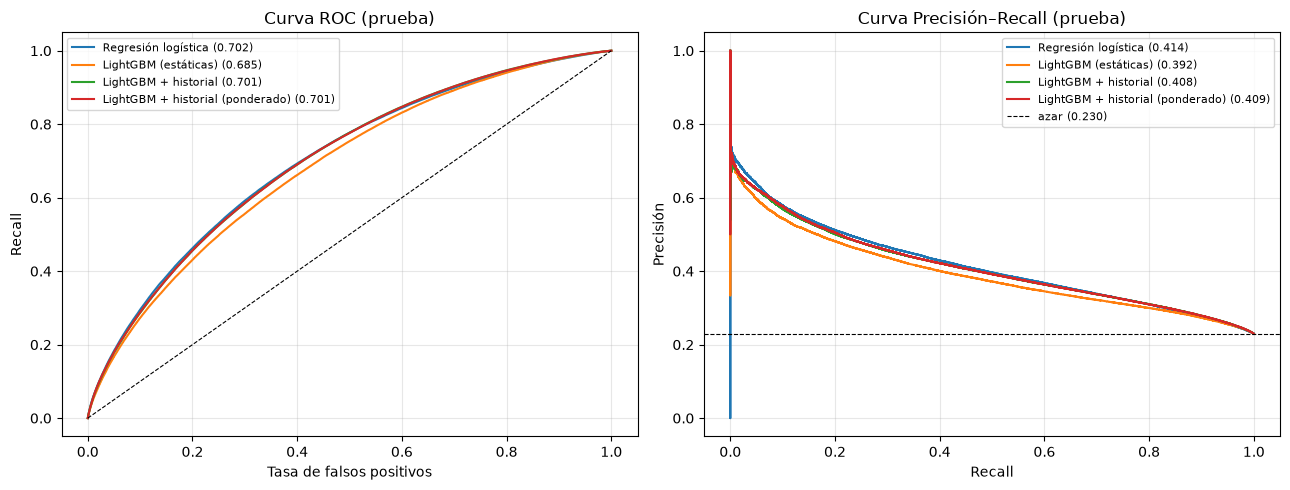

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in results.items():
    fpr, tpr, _ = roc_curve(y_test, p["test"])
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p['test']):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p["test"])
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_test, p['test']):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(title="Curva ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Recall")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8, label=f"azar ({y_test.mean():.3f})")
ax[1].set(title="Curva Precisión–Recall (prueba)", xlabel="Recall", ylabel="Precisión")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
save_fig("roc_pr_curves")

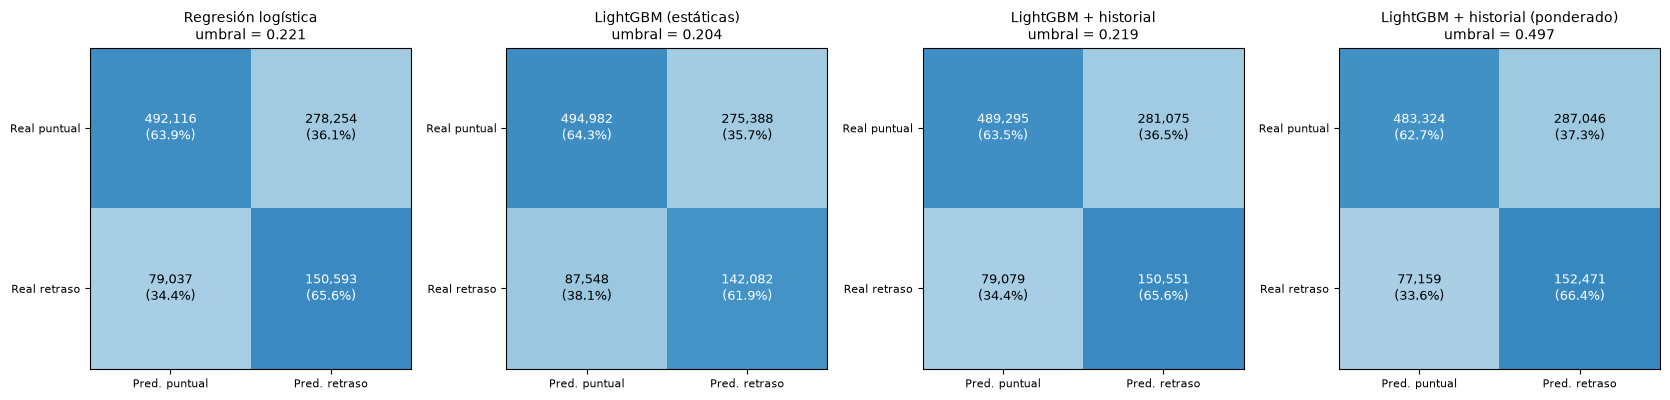

In [16]:
n_m = len(results)
fig, axes = plt.subplots(1, n_m, figsize=(4.2 * n_m, 4))
for ax, (name, p) in zip(np.atleast_1d(axes), results.items()):
    plot_confusion(ax, y_test, p["test"], thr[name], f"{name}\numbral = {thr[name]:.3f}")
save_fig("confusion_matrices")

## 9. Modelo principal: priorización, importancia y calibración

In [17]:
MAIN = "LightGBM + historial"
print("Si solo se puede vigilar el k% de vuelos con mayor riesgo:")
tk = top_k_table(y_test, results[MAIN]["test"])
display(tk)
tk.to_csv(OUT_DIR / "top_k_priorizacion.csv", index=False)

Si solo se puede vigilar el k% de vuelos con mayor riesgo:


,top_k_%,vuelos,precision,lift,recall_capturado
0,0.0100,10000,0.6478,2.8211,0.0282
1,0.0500,50000,0.5525,2.4059,0.1203
2,0.1000,100000,0.4930,2.1471,0.2147
3,0.2000,200000,0.4298,1.8718,0.3744
4,0.3000,300000,0.3894,1.6957,0.5087


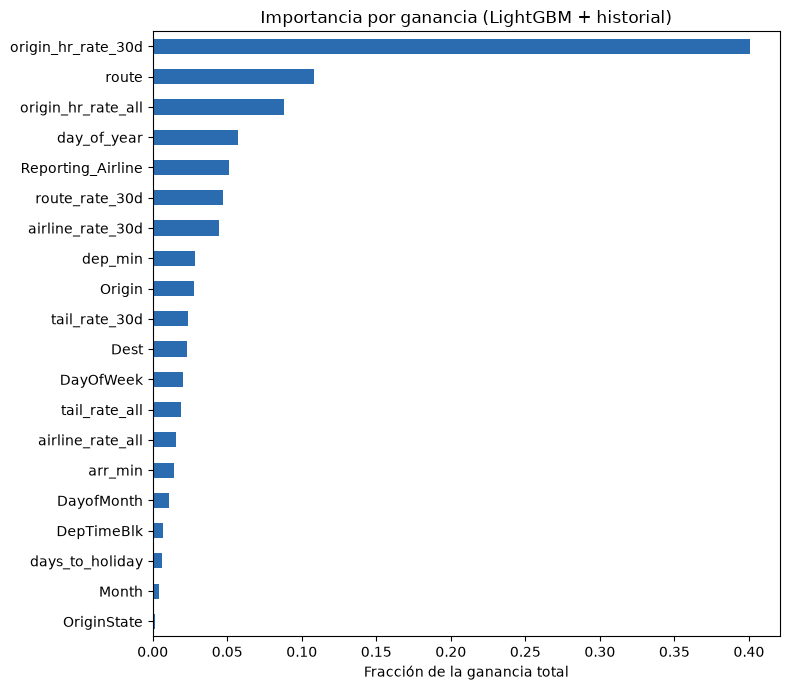

In [18]:
imp = pd.Series(m_hist.booster_.feature_importance("gain"), index=HIST_FEATURES).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(8, 7))
imp.tail(20).plot.barh(ax=ax, color="#2b6cb0")
ax.set(title="Importancia por ganancia (LightGBM + historial)", xlabel="Fracción de la ganancia total")
save_fig("feature_importance")

,sin calibrar,isotónica
brier,0.1607,0.1606
log_loss,0.4932,0.4928
ece,0.0136,0.0084


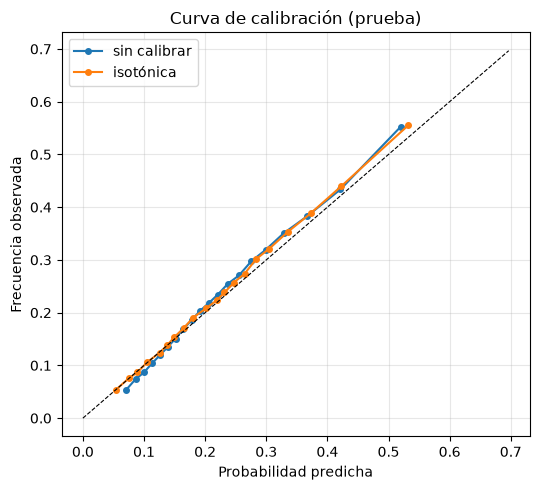

In [19]:
# Calibración (isotónica) ajustada en VALIDACIÓN y evaluada en PRUEBA, como en la propuesta.
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(results[MAIN]["val"], y_val)
p_cal = iso.predict(results[MAIN]["test"])
p_raw = results[MAIN]["test"]

calib = pd.DataFrame({
    "sin calibrar": [brier_score_loss(y_test, p_raw), log_loss(y_test, p_raw), expected_calibration_error(y_test, p_raw)],
    "isotónica":    [brier_score_loss(y_test, p_cal), log_loss(y_test, np.clip(p_cal, 1e-6, 1 - 1e-6)), expected_calibration_error(y_test, p_cal)],
}, index=["brier", "log_loss", "ece"])
display(calib)

fig, ax = plt.subplots(figsize=(5.5, 5))
for label, p in [("sin calibrar", p_raw), ("isotónica", p_cal)]:
    d = pd.DataFrame({"y": y_test, "p": p}); d["bin"] = pd.qcut(d.p, 20, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"))
    ax.plot(g.pred, g.obs, marker="o", ms=4, label=label)
lim = max(p_raw.max(), 0.6); ax.plot([0, lim], [0, lim], "k--", lw=0.8)
ax.set(title="Curva de calibración (prueba)", xlabel="Probabilidad predicha", ylabel="Frecuencia observada"); ax.legend(); ax.grid(alpha=0.3)
save_fig("calibration")

## 10. Guardar artefactos

In [20]:
m_hist.booster_.save_model(str(OUT_DIR / "lgbm_historial.txt"))
with open(OUT_DIR / "run_config.json", "w") as f:
    json.dump({"train_end": TRAIN_END, "val_end": VAL_END, "warmup_days": WARMUP_DAYS,
               "n_train": len(train), "n_val": len(val), "n_test": len(test),
               "hist_window_days": HIST_WINDOW_DAYS, "hist_smooth": HIST_SMOOTH,
               "prior": PRIOR, "seed": SEED, "features": HIST_FEATURES,
               "thresholds_val_max_f1": thr}, f, indent=2)
print("Guardado en", OUT_DIR.resolve())

Guardado en C:\Users\Usuario\OneDrive\Escritorio\Ciencia_de_datos\Proyecto Integrador\Missed-Flight-Risk-Percentage-Analysis-US\outputs\outputs_modeling


## Pendientes y supuestos
- Las muestras son un subconjunto (`N_TRAIN`, `N_EVAL`); para la corrida final subirlos o usar `None`.
- Sin ajuste de hiperparámetros (la propuesta lo contempla en *Modelado*).
- El historial usa **días** estrictamente anteriores (conservador: en operación real se conocerían también vuelos de horas antes).
- No hay variables de clima: dependen del dataset de Zenodo, aún sin integrar.
- Los feriados son los federales de EE. UU. (calendario de `pandas`), no los de Zenodo.